In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("iris_demo.csv")

train_all, test = train_test_split(
    df, test_size=0.2, stratify=df.species, random_state=42
)

train, val = train_test_split(
    train_all, test_size=0.25,
    stratify=train_all.species, random_state=42
)

print(len(train), len(val), len(test))
print(train.isna().sum())
print(train.species.value_counts())

90 30 30
sepal_length_cm    0
sepal_width_cm     0
petal_length_cm    0
petal_width_cm     0
species            0
dtype: int64
species
virginica     30
setosa        30
versicolor    30
Name: count, dtype: int64


I split the 150 flowers into training, validation, and testing sets. The training data teaches the model, validation checks its progress, and testing measures final performance. The baseline accuracy is 33.3%.

In [2]:
import torch
from sklearn.preprocessing import StandardScaler

features = list(df.columns[:-1])
classes = sorted(train.species.unique())

scaler = StandardScaler().fit(train[features])

def tensors(frame):
    X = torch.tensor(
        scaler.transform(frame[features]),
        dtype=torch.float32
    )
    y = torch.tensor(
        [classes.index(s) for s in frame.species],
        dtype=torch.long
    )
    return X, y

X_train, y_train = tensors(train)
X_val, y_val = tensors(val)

print(X_train.shape)
print(X_val.shape)
print(y_train.shape)
print(y_train.dtype)

torch.Size([90, 4])
torch.Size([30, 4])
torch.Size([90])
torch.int64


I standardized the flower measurements and converted them into PyTorch tensors. This prepares the data for training the neural network.

In [3]:
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

def make_model(dropout=0.0):
    torch.manual_seed(42)
    return nn.Sequential(
        nn.Linear(4, 64),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.Linear(64, 64),
        nn.ReLU(),
        nn.Linear(64, 3)
    )

loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=16,
    shuffle=True
)

loss_fn = nn.CrossEntropyLoss()

model = make_model()
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.0, inplace=False)
  (3): Linear(in_features=64, out_features=64, bias=True)
  (4): ReLU()
  (5): Linear(in_features=64, out_features=3, bias=True)
)


I built a neural network with two hidden layers of 64 neurons each. It uses ReLU, dropout, and cross-entropy loss to learn how to classify flowers.

In [4]:
model = make_model(dropout=0.2)
opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=0.001)

history = []
best = float('inf')
best_state = None
patience = 15
wait = 0

for epoch in range(150):
    model.train()

    for xb, yb in loader:
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()

    model.eval()
    with torch.inference_mode():
        train_loss = loss_fn(model(X_train), y_train).item()
        val_loss = loss_fn(model(X_val), y_val).item()

    history.append((train_loss, val_loss))

    if val_loss < best - 0.0001:
        best = val_loss
        best_state = {
            k: v.detach().clone()
            for k, v in model.state_dict().items()
        }
        wait = 0
    else:
        wait += 1

    if wait >= patience:
        break

model.load_state_dict(best_state)

print("Epochs:", len(history))
print("Best validation loss:", round(best, 3))

Epochs: 79
Best validation loss: 0.154


I trained my neural network using dropout and weight decay to help prevent overfitting. Early stopping saves the best model based on validation loss.

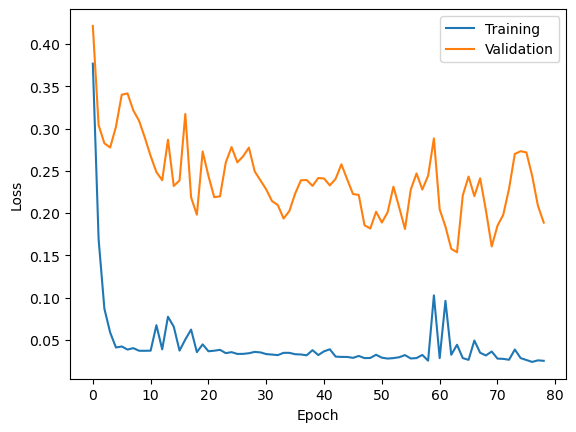

Validation accuracy: 93.33 %


In [5]:
import matplotlib.pyplot as plt

plt.plot([h[0] for h in history], label="Training")
plt.plot([h[1] for h in history], label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

model.eval()

with torch.inference_mode():
    val_pred = model(X_val).argmax(1)

accuracy = (val_pred == y_val).float().mean().item()

print("Validation accuracy:", round(accuracy * 100, 2), "%")

I graphed the training and validation losses to check for overfitting. I also measured how accurately the model predicted the validation flowers.

In [6]:
model_no_dropout = make_model(dropout=0.0)

opt = torch.optim.Adam(
    model_no_dropout.parameters(),
    lr=0.01,
    weight_decay=0.001
)

history_no_dropout = []
best_no_dropout = float("inf")
best_state_no_dropout = None
wait = 0

for epoch in range(150):
    model_no_dropout.train()

    for xb, yb in loader:
        opt.zero_grad()
        loss = loss_fn(model_no_dropout(xb), yb)
        loss.backward()
        opt.step()

    model_no_dropout.eval()

    with torch.inference_mode():
        train_loss = loss_fn(model_no_dropout(X_train), y_train).item()
        val_loss = loss_fn(model_no_dropout(X_val), y_val).item()

    history_no_dropout.append((train_loss, val_loss))

    if val_loss < best_no_dropout - 0.0001:
        best_no_dropout = val_loss
        best_state_no_dropout = {
            k: v.detach().clone()
            for k, v in model_no_dropout.state_dict().items()
        }
        wait = 0
    else:
        wait += 1

    if wait >= 15:
        break

model_no_dropout.load_state_dict(best_state_no_dropout)
model_no_dropout.eval()

with torch.inference_mode():
    pred = model_no_dropout(X_val).argmax(1)

accuracy_no_dropout = (pred == y_val).float().mean().item()

print("Epochs:", len(history_no_dropout))
print("Best validation loss:", round(best_no_dropout, 3))
print("Validation accuracy:", round(accuracy_no_dropout * 100, 2), "%")

Epochs: 26
Best validation loss: 0.215
Validation accuracy: 93.33 %


I trained a second model without dropout to compare its performance. I kept the other settings the same to see whether dropout helped.

Both models reached 93.33% accuracy. I chose the model with dropout because it had a lower validation loss of 0.154 compared to 0.215.

In [7]:
X_test, y_test = tensors(test)

model.eval()

with torch.inference_mode():
    test_pred = model(X_test).argmax(1)

test_accuracy = (test_pred == y_test).float().mean().item()

print("Final test accuracy:", round(test_accuracy * 100, 2), "%")
print("Correct predictions:", (test_pred == y_test).sum().item(), "/ 30")

Final test accuracy: 96.67 %
Correct predictions: 29 / 30


I tested my chosen model on 30 new flowers that were not used during training. This shows how well the model performs on unseen data.

Final Reflection My model achieved 93.33% validation accuracy and 96.67% test accuracy. I chose dropout because it had a lower validation loss than the model without it. Early stopping helped prevent overfitting by restoring the best model. The model correctly predicted 29 out of 30 test flowers. One limitation is the small dataset, which may affect accuracy on new data. Next time, I would try different dropout rates to see if performance improves. I learned how dropout, weight decay, and early stopping help train neural networks.